# Modeling and Checks

---
***Latent class analysis (LCA)** groups the deaths by the **situation** they happened in: what brought police and the person together, whether police were called, armed status, weapon, threat level, fleeing, mental state, and the forces used.*

***Multidimensional scaling (MDS)** through the study's dissimilarity matrix*

<hr style="border:none; border-top:0.5px solid #999">

The notebook:
- reads the indicators (`data/2_join_and_roles/indicators.parquet`) and, for the race per class correction, the descriptors (`data/2_join_and_roles/descriptors.parquet`)
- chooses the number of classes → <span style="color:yellow">k_selection.png</span>
- fits the class model, gives each death its class and checks how clearly the deaths fall into one class
- stability check over 10 new seeds
- shows what each class looks like → <span style="color:yellow">class_profiles.png</span>
- reduces the indicators with MDS → <span style="color:yellow">classes_2d.png</span>
- corrects the race mix per class for classification error (3-step)
- <span style="color:red">**saves**</span> `outputs/3_1_clustering/cluster_labels.parquet` (+ `cluster_labels.csv`): each death's id and its LCA class

### Imports and setup

---
- Applies the shared plot style

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stepmix.stepmix import StepMix
from sklearn.manifold import MDS
from sklearn.metrics import adjusted_rand_score

from shared.paths import JOIN_ROLES_DIR, OUTPUTS_DIR
from shared.config import SEED
from shared.io_utils import write_parquet
from shared.plotting import setup_plotting, save_fig, PALETTE, CLASS_COLORS, CLASS_DOT_SIZE, CLASS_DOT_ALPHA

setup_plotting()

OUT_DIR = OUTPUTS_DIR / "3_1_clustering"

### Encoding the indicators

---
**`codes`:** each indicator's categories as numbers 0, 1, 2, …, with missing left missing.
The class model and MDS read it; the class model skips a missing indicator for that death. StepMix does this by full information maximum likelihood, which uses every indicator a death has recorded and fills nothing in (Morin et al., 2025).

In [2]:
situation = pd.read_parquet(JOIN_ROLES_DIR / "indicators.parquet")
metadata_cols = ["mpv_id", "date"]  # kept for joins and checks, not clustered

INDICATORS = [c for c in situation.columns if c not in metadata_cols]

indicator_values = situation[INDICATORS].astype(object)

categories = {c: sorted(indicator_values[c].dropna().unique()) for c in INDICATORS}
for c in INDICATORS:
    print(f"  {c}: {categories[c]}")

# each category replaced by its position in the sorted list (0, 1, 2, …)
position = {c: {v: i for i, v in enumerate(categories[c])} for c in INDICATORS}
codes = pd.DataFrame({c: indicator_values[c].map(position[c]) for c in INDICATORS})

print(f"{len(codes):,} deaths × {len(INDICATORS)} indicators")

  encounter: ['domestic disturbance', 'mental health check', 'non-violent offense', 'none or generalized suspicion', 'other crime against people', 'person with a weapon', 'traffic stop', 'violent crime']
  call_for_service: ['no', 'yes']
  threat: ['attack', 'other']
  flee: ['car', 'foot', 'not fleeing', 'other']
  mental_state: ['drugs or alcohol', 'mental illness', 'neither']
  armed: ['armed', 'unarmed']
  weapon: ['armed, other', 'gun', 'knife', 'unknown weapon', 'vehicle', 'weapon, no gun']
  gunshot: [False, True]
  vehicle: [False, True]
  restraint: [False, True]
  taser: [False, True]
7,867 deaths × 11 indicators


### Number of classes selection → <span style="color:yellow">k_selection.png</span>

---
**Latent class analysis (LCA)** assumes every death belongs to one of k hidden classes, and that each class has its own chance of every category of every indicator.

**Settings:**
- k = 1 to 10 (`K_RANGE`), one class more at a time, the standard procedure in Weller et al. (2020)
- 20 random starts per fit (`N_INIT`). Expectation-maximization (EM) is only sure to reach a local maximum, so it is run from several starting points to find the best solution with high probability (Morin et al., 2025)

Each fit gives its **log-likelihood** (how well it explains the deaths) and its number of parameters (more with every class), and from them two fit scores (both lower = better): **BIC** and **SABIC** (sample-size adjusted BIC; Sclove, 1987), which penalize every extra parameter, so a k only wins if its better fit is worth the extra classes.

<hr style="border:none; border-top:0.5px solid #999">

**Choosing k (`best_k`):** BIC is lowest at 8, while SABIC keeps falling up to 10, so the two scores do not agree on k. The choice reads the curve and the classes together, as Weller et al. (2020) recommend:
   - SABIC's fall shrinks to about a quarter after the 8th class (273 → 70, then 8): a 9th and a 10th class buy little
   - whether the 8 classes each read as a distinct situation is checked in "Class profiles"
   - the smallest class, 129 vehicle deaths (1.6%), is under the older 5% rule, which Weller et al. (2020) report as relaxed: what counts is whether the fit supports the model and the small class makes sense

       loglik  parameters         BIC       SABIC  SABIC_drop
k                                                            
1  -50981.271          24  102177.832  102101.565         NaN
2  -48462.300          49   97364.151   97208.439    4893.126
3  -46385.522          74   93434.857   93199.700    4008.739
4  -45777.265          99   92442.602   92128.000    1071.700
5  -45277.751         124   91667.836   91273.789     854.211
6  -44910.260         149   91157.115   90683.623     590.166
7  -44665.228         174   90891.310   90338.373     345.250
8  -44456.477         199   90698.071   90065.689     272.685
9  -44349.202         224   90707.780   89995.953      69.735
10 -44272.558         249   90778.755   89987.482       8.471

Chosen k: 8


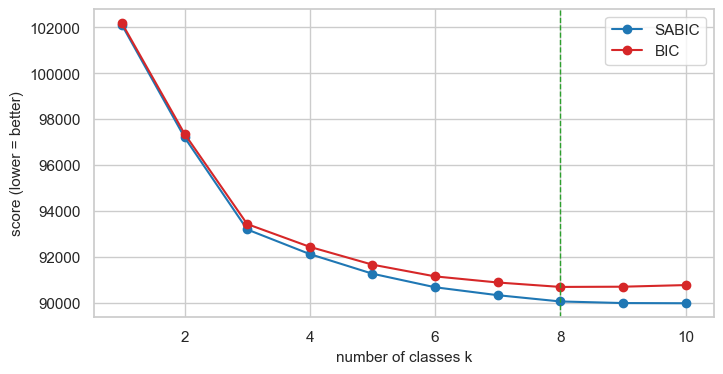

In [3]:
K_RANGE = range(1, 11)
N_INIT = 20


def fit_lca(k: int, seed: int = SEED) -> StepMix:
    """An LCA with k classes on `codes`, `N_INIT` random starts, the best kept."""
    return StepMix(
        n_components=k, measurement="categorical_nan",  # categories, with missing values skipped
        n_init=N_INIT, abs_tol=1e-6,  # stop when the fit improves by less than 1e-6 per death
        random_state=seed, progress_bar=0,  # 0: no progress bar, which StepMix otherwise draws for every fit
    ).fit(codes)


n = len(codes)
scores_per_k = []
for k in K_RANGE:
    model = fit_lca(k)
    loglik = model.score(codes) * n  # `score` is the mean log-likelihood per death
    scores_per_k.append({
        "k": k,
        "loglik": loglik,
        "parameters": model.n_parameters,
        # both scores: -2 · log-likelihood + a penalty per parameter
        # (BIC from StepMix: ln n; SABIC by Sclove's formula)
        "BIC": model.bic(codes),
        "SABIC": -2 * loglik + model.n_parameters * np.log((n + 2) / 24),
    })

k_selection = pd.DataFrame(scores_per_k).set_index("k")
k_selection["SABIC_drop"] = -k_selection["SABIC"].diff()  # how much SABIC falls when the k-th class is added
print(k_selection.round(3).to_string())

best_k = 8  # the choice argued above
print(f"\nChosen k: {best_k}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_selection.index, k_selection["SABIC"], marker="o", color=PALETTE[0], label="SABIC")
ax.plot(k_selection.index, k_selection["BIC"], marker="o", color=PALETTE[1], label="BIC")
ax.axvline(best_k, color=PALETTE[2], linestyle="--", linewidth=1)
ax.set(xlabel="number of classes k", ylabel="score (lower = better)")
ax.legend()
save_fig(fig, "k_selection", OUT_DIR)

### Class assignment and relative entropy

---
- **The k = 8 model, fitted again** (`fit_lca(best_k)`) on the same settings
- **Each death's chance of each class** (`predict_proba`): for every death, how likely each of the 8 classes is; its 8 chances add up to 100%. Weller et al. (2020) call these chances posterior class membership probabilities: posterior = after the model has seen the death's recorded indicators
- **Each death's class is its most likely one** (`argmax`: the class with the highest chance), its **modal class**. Weller et al. (2020) assign each case by these probabilities once the model is chosen; the code takes the most likely class. The assignment is not guaranteed to be right, since membership is a probability: the clarity numbers below and "Race per class, corrected for classification error" measure how much that matters
- **The classes are numbered by size**, largest first (`bincount` counts the deaths per class, `argsort` orders the classes, the chance columns are reordered to match): StepMix's own class numbers are arbitrary, and size gives them an order a reader can follow
- **Relative entropy** (0 to 1): 1 = every death sits clearly in one class, near 0 = the classes blur into each other. Weller et al. (2020) read above .8 as acceptable and below .6 as hard to publish, and ask that entropy be reported but not used to choose k
- **Per class, the mean chance of the deaths assigned to it:** how sure the model is about its own members. These are the diagonal of Weller et al.'s average latent class posterior probability matrix (2020): above .90 is ideal, .80 to .90 acceptable when the other criteria are met, and below .80 unacceptable
- **Where the study differs:** Weller et al.'s report list also asks for the smallest value off that matrix's diagonal, the chance of a class's members being assigned to another class; it is not computed here

In [4]:
lca = fit_lca(best_k)
proba = lca.predict_proba(codes)

modal_class = proba.argmax(axis=1)  # argmax: each death's most likely class
class_sizes = np.bincount(modal_class, minlength=best_k)  # bincount: how many deaths per class
order = np.argsort(-class_sizes)  # argsort of the negative counts: the class numbers, largest class first

# reorder the chance columns so class 0 is the largest
proba = proba[:, order]
lca_class = proba.argmax(axis=1)  # the modal class, renumbered
entropy = lca.relative_entropy(codes)
print(f"Relative entropy: {entropy:.3f}")

# `max(axis=1)` = the chance of the modal class
per_class = pd.DataFrame({
    "deaths": np.bincount(lca_class, minlength=best_k),
    "mean_chance": pd.Series(proba.max(axis=1)).groupby(lca_class).mean().round(3),
})
per_class.index.name = "class"  # class 0 = the largest
print(per_class.to_string())

Relative entropy: 0.774
       deaths  mean_chance
class                     
0        2418        0.818
1        1598        0.850
2        1141        0.793
3         937        0.787
4         694        0.753
5         595        0.894
6         355        0.981
7         129        0.997


### Stability over seeds

---
**The model is refitted from 10 new seeds**, each again from 20 random starts.

**Computed for every refit:**
- log-likelihood against the main fit's (`loglik_diff`, near 0 = the same solution)
- **adjusted Rand index** (**ARI**; Hubert & Arabie, 1985: 1 = the same classes, 0 = no better than chance)

A refit counts as reaching the main solution when its log-likelihood is less than 1 below the main fit's: the study's own cut-off.

In [5]:
best_loglik = lca.score(codes) * n

rows = []
for seed in range(10):
    refit = fit_lca(best_k, seed=seed)
    rows.append({
        "seed": seed,
        "loglik_diff": refit.score(codes) * n - best_loglik,
        "ARI": adjusted_rand_score(lca_class, refit.predict(codes)),
    })
stability = pd.DataFrame(rows).set_index("seed")
print(stability.round(3).to_string())

same = stability["loglik_diff"] > -1  # reached the main fit's solution (within 1 log-likelihood unit)
reached = stability[same]
ari_low, ari_high = reached["ARI"].min(), reached["ARI"].max()
print(f"\nReached the main solution: {len(reached)} of {len(stability)}; ARI {ari_low:.3f}-{ari_high:.3f}")

      loglik_diff    ARI
seed                    
0           0.044  0.987
1           0.614  0.989
2           0.011  0.994
3           0.350  0.990
4          -0.052  0.987
5           0.549  0.986
6         -76.043  0.523
7           0.012  0.993
8           0.025  0.978
9          -0.005  0.987

Reached the main solution: 9 of 10; ARI 0.978-0.994


### Class profiles → <span style="color:yellow">class_profiles.png</span>

---
- **Heat map** (<span style="color:yellow">class_profiles.png</span>): how common each category is inside each class (deaths with that indicator missing left out; e.g. weapon counts only the armed deaths)

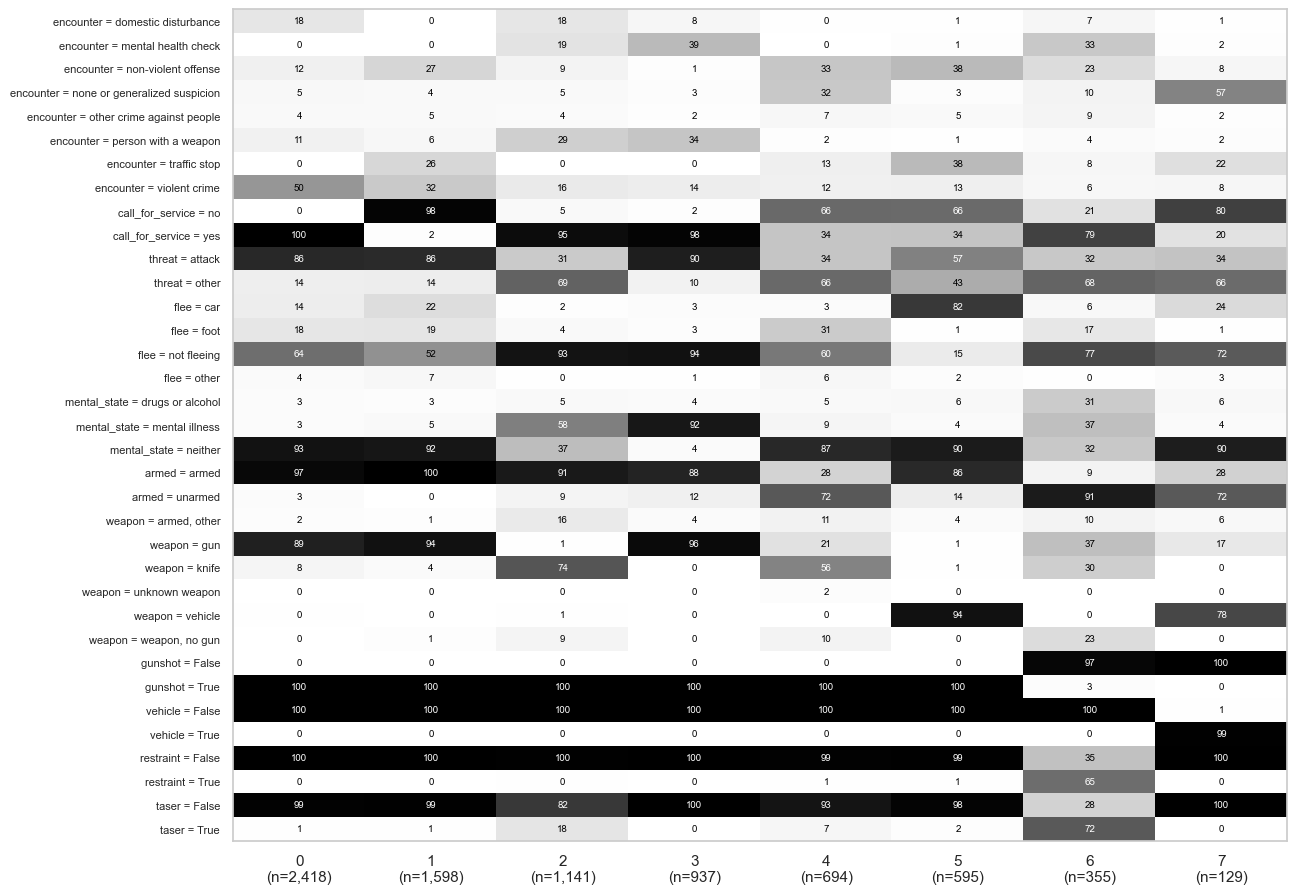

In [6]:
# `normalize="columns"`: each class's categories add up to 100%
profile = pd.concat({c: pd.crosstab(indicator_values[c], lca_class, normalize="columns") * 100 for c in INDICATORS})
sizes = per_class["deaths"].to_numpy()

fig, ax = plt.subplots(figsize=(1.2 * best_k + 4, 0.28 * len(profile) + 1))
ax.grid(False)  # the project style's grid lines would cross the cells
ax.imshow(profile.values, cmap="Greys", vmin=0, vmax=100, aspect="auto")
ax.set_yticks(range(len(profile)), [f"{c} = {v}" for c, v in profile.index], fontsize=8)
ax.set_xticks(range(best_k), [f"{j}\n(n={n:,})" for j, n in enumerate(sizes)])
for (i, j), v in np.ndenumerate(profile.values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 55 else "black")
save_fig(fig, "class_profiles", OUT_DIR)

### Dimensionality reduction with MDS → <span style="color:yellow">classes_2d.png</span>

---
**Multidimensional scaling (MDS)** places the deaths so that their distances match the study's **`mismatch_dissimilarity`**.

The study's own dissimilarity compares one death with another only on the indicators both have recorded, as the share of those on which the two differ (0: they agree on all, 1: they differ on all), and it counts any two different categories as equally different.

MDS computes a first layout from `D` and places all deaths on a plane, which are then incrementally fine-tuned until their distances match their dissimilarities (D’s numbers) as closely as possible.
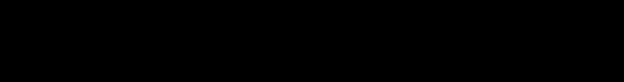
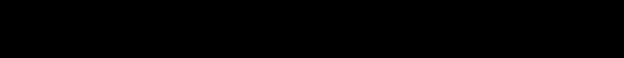

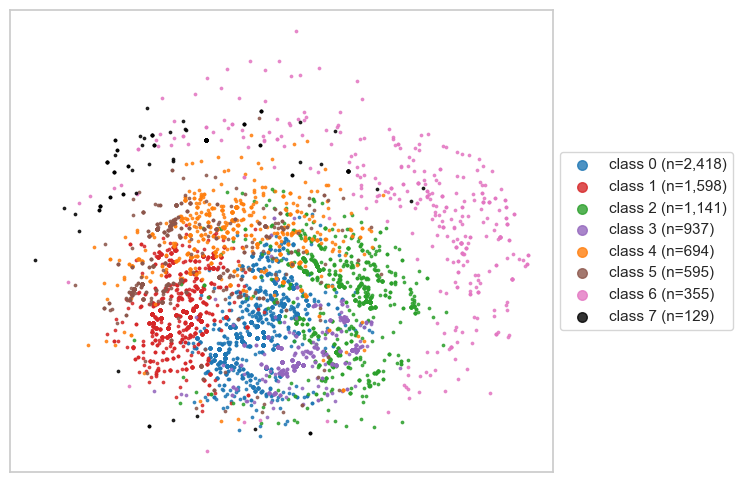

In [7]:
def mismatch_dissimilarity(rows: np.ndarray) -> np.ndarray:
    """For every pair of deaths: the share of indicators on which they differ, among the indicators both have recorded."""
    differ = np.zeros((len(rows), len(rows)))
    compared = np.zeros((len(rows), len(rows)))
    for col in rows.T:
        both = ~np.isnan(col)[:, None] & ~np.isnan(col)[None, :]  # recorded for both deaths
        differ += both & (col[:, None] != col[None, :])
        compared += both
    return differ / compared


D = mismatch_dissimilarity(codes.values)

# MDS on the dissimilarity, to 2 dimensions (`metric="precomputed"`: the distances are given, not computed), started from classical MDS (`n_init=1`: that one start only)
embedding = MDS(metric="precomputed", init="classical_mds", n_init=1).fit_transform(D)

fig, ax = plt.subplots(figsize=(7, 6))
for j in range(best_k):
    in_class = lca_class == j
    ax.scatter(embedding[in_class, 0], embedding[in_class, 1], s=CLASS_DOT_SIZE, alpha=CLASS_DOT_ALPHA, color=CLASS_COLORS[j], label=f"class {j} (n={(lca_class == j).sum():,})")
ax.set(xticks=[], yticks=[])
ax.legend(markerscale=4, loc="center left", bbox_to_anchor=(1, 0.5))  # right of the plot, covering no death
save_fig(fig, "classes_2d", OUT_DIR)

### Race per class, corrected for classification error (three-step BCH)

---
Because the model's relative entropy is 0.774, the descriptors are read in each death's most likely class. Race per class is one of the study's core equity numbers, so it is re-estimated with the three-step method and Bolck-Croon-Hagenaars (BCH) correction (Bolck et al., 2004, as cited in Morin et al., 2025) that accounts for uncertainty (stepmix `correction="BCH"`).

- **Step 1:** the same class model is fitted on the indicators
- **Step 2:** each death goes to its most likely class, and the model estimates how often a death of one class lands in another
- **Step 3:** each class's race shares are estimated with the deaths re-weighted to cancel those misplacements (the BCH weights). Uncorrected, misplaced deaths bring other classes' race mix in and make the classes look more alike than they are (Morin et al., 2025)
- **Matching:** the three-step classes are matched to the main classes by the deaths they share
- **Counted vs corrected:** counted = the race of the deaths assigned to each class, without step 3's weights; both are printed with the largest difference

In [8]:
# each death's race, in the order of `situation`
descriptors = pd.read_parquet(JOIN_ROLES_DIR / "descriptors.parquet").set_index("mpv_id")
race = descriptors.loc[situation["mpv_id"], "race"]

# race as numbers 0-4, in the order of `race_cats` (AIAN = American Indian and Alaska Native)
race_cats = ["white", "black", "hispanic", "asian", "AIAN"]
race_position = {r: i for i, r in enumerate(race_cats)}
race_codes = race.map(race_position)  # missing race stays missing

three_step = StepMix(
    n_components=best_k, measurement="categorical_nan",  # step 1
    n_steps=3,
    assignment="modal",  # step 2
    structural="categorical_nan", correction="BCH",  # step 3
    n_init=N_INIT, abs_tol=1e-6, random_state=SEED, progress_bar=0,
).fit(codes, race_codes)
labels_3 = three_step.predict(codes)
print(f"3-step classes vs main classes (ARI): {adjusted_rand_score(lca_class, labels_3):.3f}")
match = pd.crosstab(labels_3, lca_class).idxmax(axis=1)  # each 3-step class -> the main class it shares the most deaths with
assert match.nunique() == best_k, "the 3-step classes do not match the main classes one to one"

sm = three_step.get_sm_df()  # the corrected race shares of each 3-step class
corrected = pd.DataFrame({match[c]: sm[c].to_numpy() * 100 for c in sm.columns}, index=race_cats)
corrected = corrected[list(range(best_k))]  # the columns in the main classes' order

# the modal shares (percent of the recorded race in each modal class), and the difference between the two
modal_shares = {}
for j in range(best_k):
    recorded = race[lca_class == j].dropna()
    modal_shares[j] = [(recorded == r).mean() * 100.0 for r in race_cats]
modal = pd.DataFrame(modal_shares, index=race_cats)
diff = (corrected - modal).abs()
largest_diff, largest_class = diff.to_numpy().max(), diff.max().idxmax()
print(f"\nLargest difference between modal and corrected race shares: {largest_diff:.1f} percentage points (class {largest_class})")

race_check = pd.concat({"modal": modal, "corrected": corrected}, axis=1).swaplevel(axis=1).sort_index(axis=1)
print(race_check.round(1).to_string())

3-step classes vs main classes (ARI): 1.000

Largest difference between modal and corrected race shares: 6.1 percentage points (class 3)
                 0               1               2               3               4               5               6               7      
         corrected modal corrected modal corrected modal corrected modal corrected modal corrected modal corrected modal corrected modal
white         47.4  48.4      43.5  43.9      50.5  51.8      76.1  69.9      41.1  42.9      49.2  48.7      36.7  37.0      45.7  45.7
black         28.7  28.0      35.1  34.2      18.6  19.6      13.2  16.0      30.9  30.0      28.5  28.7      36.3  36.1      33.6  33.6
hispanic      20.3  20.0      19.0  19.2      25.6  23.6       9.1  11.9      20.6  20.8      20.9  20.8      22.6  22.6      19.8  19.8
asian          1.6   1.6       1.2   1.2       3.2   2.9       1.0   1.3       2.5   2.3       0.4   0.5       2.6   2.6       0.9   0.9
AIAN           2.0   2.0       1.2   1.4 

### Save the labels

---

In [9]:
cluster_labels = pd.DataFrame({
    "mpv_id": situation["mpv_id"],
    "lca_class": lca_class,
})
write_parquet(cluster_labels, OUT_DIR / "cluster_labels.parquet")
print(f"Saved: cluster_labels.parquet + cluster_labels.csv ({len(cluster_labels):,} rows)")

Saved: cluster_labels.parquet + cluster_labels.csv (7,867 rows)
